# H2 gradient direction and retrieval cost

The probe varies the attention-mixing coefficient \(d\) and measures the mean language-model loss gradient \(g(d)=\partial L/\partial d\) for each supporting-to-distractor ratio. REVIVE compares its predicted decision score with a separate operational threshold \(\tau\) when deciding whether to retrieve.

### 1.1 Load H2 Gradient Results

Load the aggregated H2 gradient results from `gradient_summary.csv`.

The file contains the mean gradient of the LM loss with respect to the retrieval decision score \(d\), grouped by hop count, retrieval ratio, and decision score.

In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("gradient_results/plots/gradient_summary.csv")

df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

df.head()

Shape: (528, 5)
Columns: ['hop', 'retrieval_ratio', 'decision_score', 'mean_gradient', 'n_samples']


,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
0,2-hop,3:0,0.0000,NaN,0
1,2-hop,3:0,0.0312,NaN,0
2,2-hop,3:0,0.0625,NaN,0
3,2-hop,3:0,0.0938,NaN,0
4,2-hop,3:0,0.1250,NaN,0


### 1.2 Extract Total Data

Select only the `Total` rows from the H2 gradient results.

The `Total` data aggregates the gradient results across all hop counts and is used for determining the gradient-informed threshold.

In [2]:
total_df = df[df["hop"] == "Total"].copy()

print(f"Shape: {total_df.shape}")

total_df.head()

Shape: (132, 5)


,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
396,Total,3:0,0.0000,-0.286350,494
397,Total,3:0,0.0312,-0.220648,494
398,Total,3:0,0.0625,-0.138676,494
399,Total,3:0,0.0938,-0.224021,494
400,Total,3:0,0.1250,-0.035823,494


### 1.3 Extract Characteristic Decision Scores

For each retrieval ratio, identify a characteristic decision score from the gradient curve:

- `0:3`: select the decision score with the **maximum positive gradient**.
- `1:2`, `2:1`, `3:0`: select the decision score with the **minimum gradient**.

These points represent the peak or valley of the corresponding gradient curves and will be used to estimate the threshold.

In [3]:
ratios = ["0:3", "1:2", "2:1", "3:0"]

characteristic_rows = {}

for ratio in ratios:
    ratio_df = total_df[
        (total_df["retrieval_ratio"] == ratio) &
        (total_df["n_samples"] > 0)
    ].dropna(subset=["mean_gradient"])

    if ratio == "0:3":
        row = ratio_df.loc[ratio_df["mean_gradient"].idxmax()]
    else:
        row = ratio_df.loc[ratio_df["mean_gradient"].idxmin()]

    characteristic_rows[ratio] = row

characteristic_df = pd.DataFrame(characteristic_rows).T

characteristic_df[
    ["decision_score", "mean_gradient", "n_samples"]
]

,decision_score,mean_gradient,n_samples
0:3,0.375,0.401607,1024
1:2,0.4375,-1.235579,1024
2:1,0.4375,-2.123264,1024
3:0,0.4375,-2.478448,494


### 1.4 Select a fixed heuristic threshold

The all-distractor curve peaks at \(d=0.375\), and the three supporting-condition curves reach their minima at \(d=0.4375\). These features motivate examining the neighborhood around \(d=0.4\)?\(0.44\). We use the historical REVIVE value \(\tau=0.4297\) as a fixed heuristic within that neighborhood. The extrema motivate the region. They do not optimize the gate or yield that exact value.

The earlier notebook averaged the extrema to obtain \(0.421875\). According to the project author, historical REVIVE used \(0.4297\) because of a numerical entry mistake.

In [4]:
tau = 0.4297
print(f"Fixed heuristic retrieval threshold: tau = {tau:.4f}")

Fixed heuristic retrieval threshold: tau = 0.4297


### 1.5 Select the cost-analysis range

Show the full gradient curves to retain the characteristic extrema. For the cost plot, retain observed grid points at or above \(\tau\).

In [5]:
threshold_df = total_df.loc[total_df["decision_score"] >= tau].copy()
threshold_df.head()

,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
410,Total,3:0,0.4375,-2.478448,494
411,Total,3:0,0.4688,-1.874388,494
412,Total,3:0,0.5000,-1.129466,494
413,Total,3:0,0.5312,-0.726315,494
414,Total,3:0,0.5625,-0.577728,494


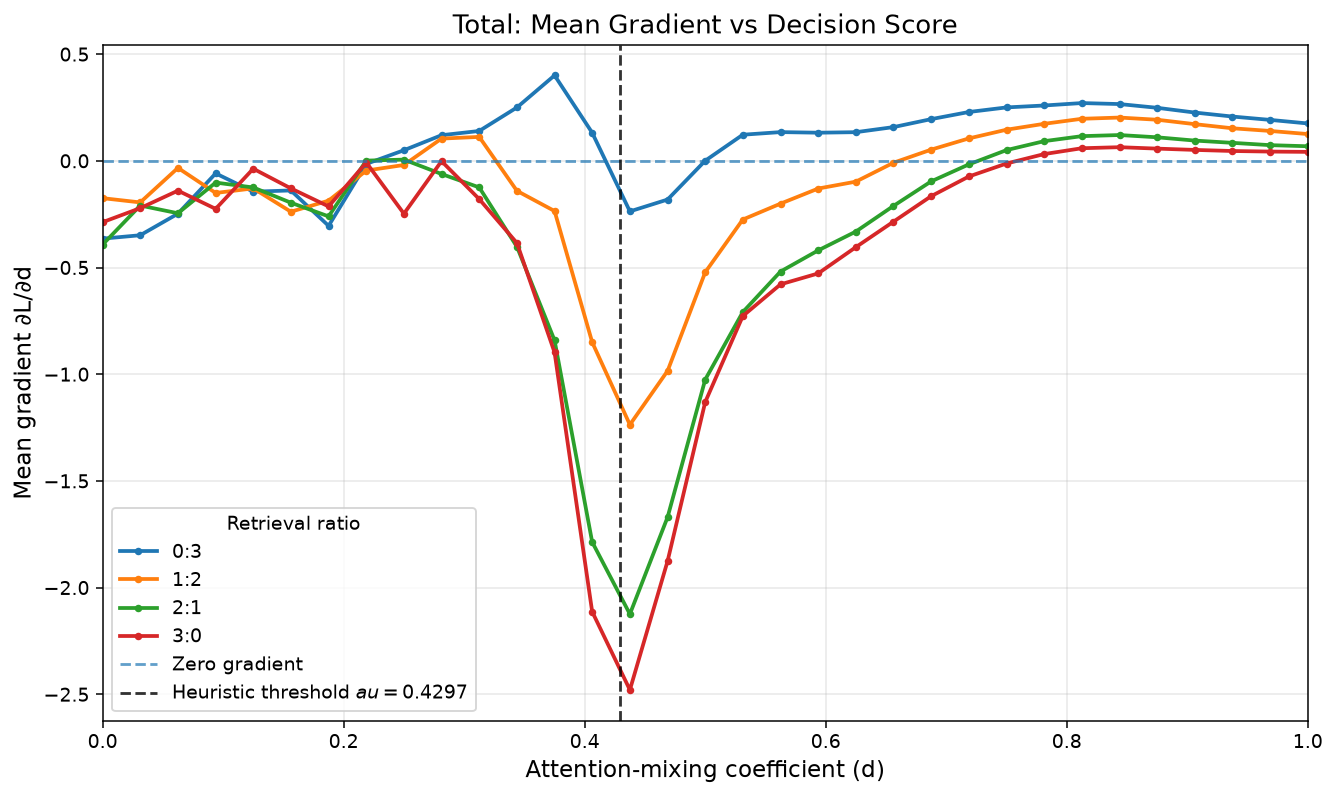

In [6]:
import matplotlib.pyplot as plt


OUTPUT_PATH = Path(
    "gradient_results/plots/gradient_vs_decision_score_total_with_threshold.png"
)

plt.figure(figsize=(10, 6))

# Same color order as the LM-loss plot:
# 0:3 → blue
# 1:2 → orange
# 2:1 → green
# 3:0 → red
for ratio in ["0:3", "1:2", "2:1", "3:0"]:
    ratio_df = total_df[
        total_df["retrieval_ratio"] == ratio
    ].sort_values("decision_score")

    if ratio_df.empty:
        continue

    plt.plot(
        ratio_df["decision_score"],
        ratio_df["mean_gradient"],
        marker="o",
        markersize=3,
        linewidth=2,
        label=ratio,
    )

# Zero-gradient reference
plt.axhline(
    y=0.0,
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label="Zero gradient",
)

# Threshold reference
plt.axvline(
    x=tau,
    color="black",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label=fr"Heuristic threshold $	au={tau:.4f}$",
)

plt.xlabel(
    "Attention-mixing coefficient (d)",
    fontsize=12,
)

plt.ylabel(
    "Mean gradient ∂L/∂d",
    fontsize=12,
)

plt.title(
    "Total: Mean Gradient vs Decision Score",
    fontsize=14,
)

plt.xlim(0, 1)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    title="Retrieval ratio"
)

plt.tight_layout()

plt.show()

## 2. Retrieval cost analysis

Adding a linear penalty \(\lambda d\) shifts the loss derivative from \(g(d)\) to \(g(d)+\lambda\). The horizontal levels \(-\lambda\) for \(\lambda\in\{0,0.05,0.1\}\) show where this combined gradient changes sign. Mark crossings by linear interpolation between adjacent observed points in the cost-analysis range. These crossings describe the local effect of the penalty on \(d\).


Intersection decision scores:
d = 0.482567
d = 0.491141
d = 0.499714
d = 0.621572
d = 0.641357
d = 0.660195
d = 0.686194
d = 0.705241
d = 0.709377
d = 0.726012
d = 0.730205
d = 0.758080


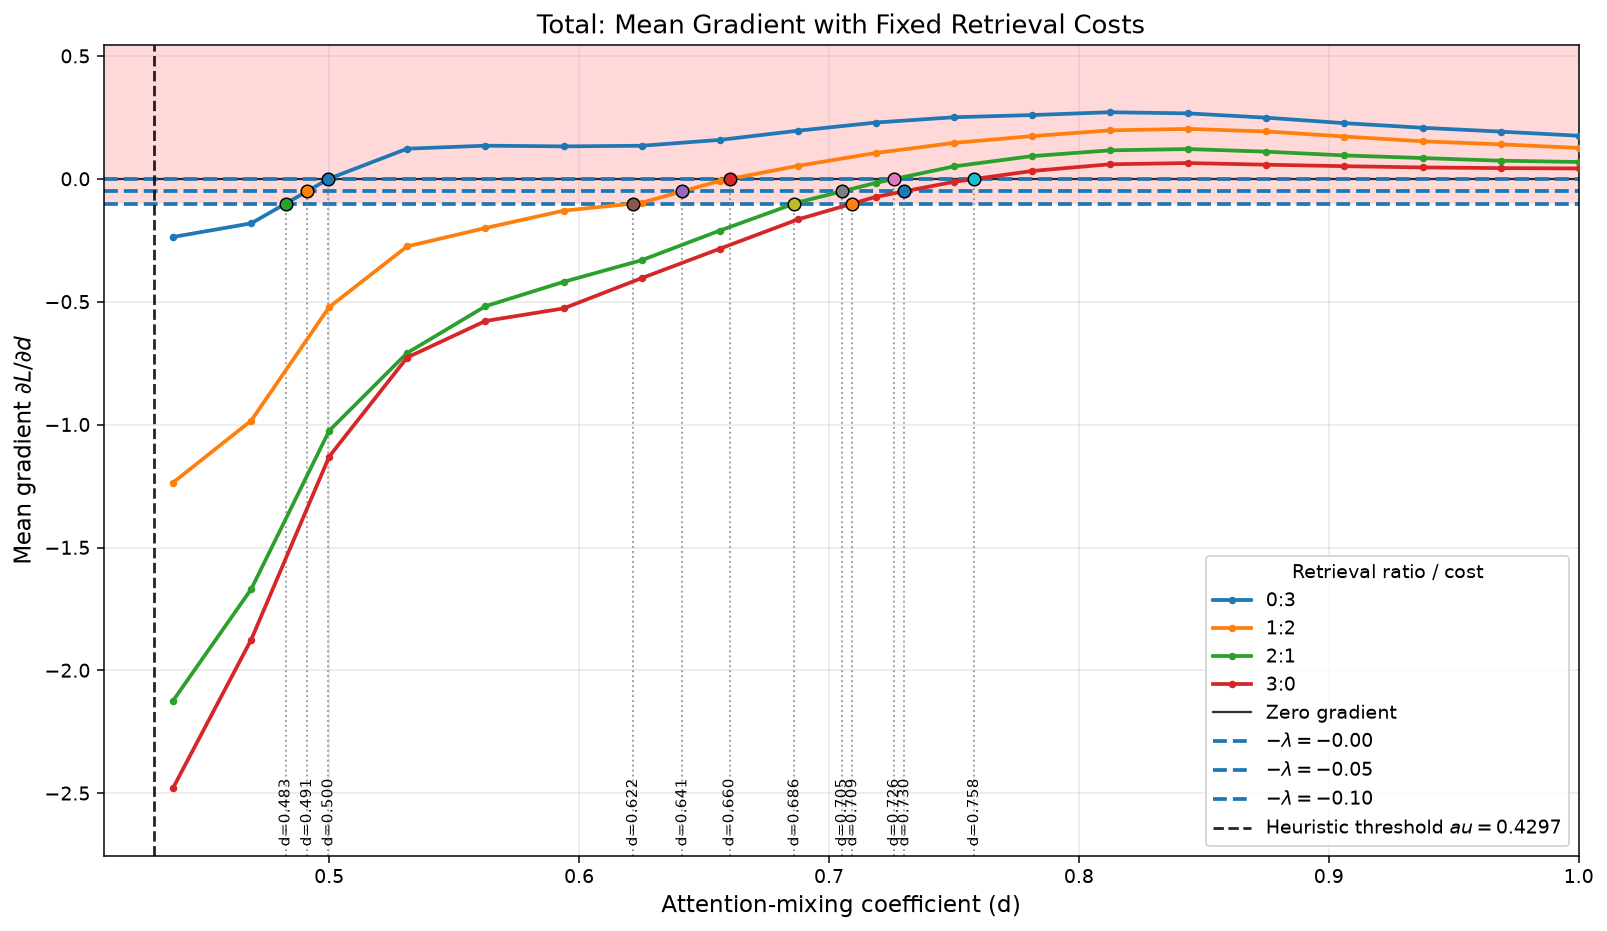

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed retrieval-cost values
RETRIEVAL_COSTS = [0.0, 0.05, 0.1]

fig, ax = plt.subplots(figsize=(12, 7))

# Plot gradient curves and retain their data for intersection detection.
ratios = ["0:3", "1:2", "2:1", "3:0"]
curve_data = {}

for ratio in ratios:
    ratio_df = threshold_df[
        threshold_df["retrieval_ratio"] == ratio
    ].sort_values("decision_score")

    if ratio_df.empty:
        continue

    x = ratio_df["decision_score"].to_numpy(dtype=float)
    y = ratio_df["mean_gradient"].to_numpy(dtype=float)

    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    if len(x) == 0:
        continue

    curve_data[ratio] = (x, y)

    ax.plot(
        x,
        y,
        marker="o",
        markersize=3,
        linewidth=2,
        label=ratio,
        zorder=3,
    )

# Set plot limits.
y_values = threshold_df["mean_gradient"].dropna().to_numpy()

y_min = min(y_values.min(), -max(RETRIEVAL_COSTS))
y_max = max(y_values.max(), 0.0)

y_range = y_max - y_min
if y_range == 0:
    y_range = 1.0

y_min -= 0.10 * y_range
y_max += 0.10 * y_range

ax.set_ylim(y_min, y_max)

# Uniform red background from -0.1 to the top.
red_start = max(-0.1, y_min)

if y_max > red_start:
    ax.axhspan(
        red_start,
        y_max,
        color="red",
        alpha=0.15,
        linewidth=0,
        zorder=0,
    )

# Zero-gradient reference.
ax.axhline(
    y=0.0,
    color="black",
    linewidth=1.2,
    alpha=0.8,
    label="Zero gradient",
    zorder=2,
)

# Fixed negative retrieval-cost reference lines.
for cost in RETRIEVAL_COSTS:
    ax.axhline(
        y=-cost,
        linestyle="--",
        linewidth=2,
        label=fr"$-\lambda = {-cost:.2f}$",
        zorder=2,
    )

# Find intersections and project them onto the x-axis.
# Linear interpolation is used between adjacent observed points.
intersection_xs = []

for ratio, (x, y) in curve_data.items():
    for cost in RETRIEVAL_COSTS:
        target_y = -cost
        differences = y - target_y

        for i in range(len(x) - 1):
            x1, x2 = x[i], x[i + 1]
            f1, f2 = differences[i], differences[i + 1]

            # Skip non-finite segments.
            if not np.isfinite([x1, x2, f1, f2]).all():
                continue

            # Exact intersection at the left endpoint.
            if np.isclose(f1, 0.0, atol=1e-12):
                d_intersect = x1

            # A strict sign change means the segment crosses the target.
            elif f1 * f2 < 0:
                d_intersect = x1 + (target_y - y[i]) * (
                    (x2 - x1) / (y[i + 1] - y[i])
                )

            else:
                continue

            # Keep only intersections in the displayed x-range.
            if tau <= d_intersect <= 1.0:
                intersection_xs.append(d_intersect)

                # Mark the intersection on the curve.
                ax.scatter(
                    d_intersect,
                    target_y,
                    s=45,
                    edgecolors="black",
                    linewidths=0.8,
                    zorder=6,
                )

                # Project vertically down to the x-axis.
                ax.vlines(
                    d_intersect,
                    y_min,
                    target_y,
                    colors="gray",
                    linestyles=":",
                    linewidth=1.0,
                    alpha=0.8,
                    zorder=2,
                )

                # Label the projected decision score near the x-axis.
                ax.annotate(
                    f"d={d_intersect:.3f}",
                    xy=(d_intersect, y_min),
                    xytext=(0, 5),
                    textcoords="offset points",
                    rotation=90,
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    color="black",
                    clip_on=False,
                    zorder=7,
                )

# Fixed heuristic operational threshold.
ax.axvline(
    x=tau,
    color="black",
    linestyle="--",
    linewidth=1.5,
    alpha=0.85,
    label=fr"Heuristic threshold $	au={tau:.4f}$",
    zorder=4,
)

ax.set_xlabel("Attention-mixing coefficient (d)", fontsize=12)
ax.set_ylabel(r"Mean gradient $\partial L / \partial d$", fontsize=12)
ax.set_title(
    "Total: Mean Gradient with Fixed Retrieval Costs",
    fontsize=14,
)

ax.set_xlim(tau - 0.02, 1.0)
ax.set_xticks(np.linspace(0.5, 1.0, 6))

# Extra bottom margin for projected labels.
ax.grid(True, alpha=0.3, zorder=1)
ax.legend(title="Retrieval ratio / cost")

fig.subplots_adjust(bottom=0.20)
fig.tight_layout()

if intersection_xs:
    print("\nIntersection decision scores:")
    for d_value in sorted(intersection_xs):
        print(f"d = {d_value:.6f}")
else:
    print("\nNo intersections found in the displayed decision-score range.")

plt.show()